# Mô Hình Mạng Tích Chập (CNN) Thuần NumPy Từ Đầu Trên MNIST
Notebook triển khai hoàn chỉnh mạng CNN từ đầu (Pure NumPy) gồm 2 phiên bản:
1. **Baseline Model:** Conv2D đơn giản (4 filters), SGD Momentum.
2. **Improved Model:** Conv2D dung lượng cao hơn (8 filters), Dense(64), Adam Optimizer, He Normal Init.
3. **So sánh đối chứng:** Đường cong huấn luyện, báo cáo chỉ số và Ma trận nhầm lẫn (Confusion Matrix).


In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 11

FIGURES_DIR = '../reports/figures'
os.makedirs(FIGURES_DIR, exist_ok=True)


### 1. Nạp Dữ Liệu & Tiền Xử Lý
Đọc dữ liệu từ `mnist.npz`, chuẩn hóa giá trị điểm ảnh về đoạn [0, 1] và định dạng tensor 4D `(Batch, Channel, Height, Width)`.


In [2]:
DATA_PATH = '../data/mnist.npz'
if not os.path.exists(DATA_PATH):
    DATA_PATH = 'src/Assigment 04/mnist/data/mnist.npz'

data = np.load(DATA_PATH)
# Lấy 25,000 mẫu train để huấn luyện nhanh với Pure NumPy và toàn bộ 10,000 mẫu test
X_train_raw, y_train_raw = data['X_train'][:25000], data['y_train'][:25000]
X_test_raw, y_test_raw = data['X_test'], data['y_test']

# Reshape sang (N, 1, 28, 28) và chuẩn hóa [0, 1]
X_train = (X_train_raw[:, np.newaxis, :, :] / 255.0).astype(np.float32)
y_train = y_train_raw.astype(np.int64)

X_test = (X_test_raw[:, np.newaxis, :, :] / 255.0).astype(np.float32)
y_test = y_test_raw.astype(np.int64)

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape}, y_test shape:  {y_test.shape}")


X_train shape: (25000, 1, 28, 28), y_train shape: (25000,)
X_test shape:  (10000, 1, 28, 28), y_test shape:  (10000,)


### 2. Định Nghĩa Các Lớp CNN Thuần NumPy (Self-Contained)
Bao gồm: `im2col`/`col2im` ma trận hóa, `Conv2D`, `MaxPool2D`, `ReLU`, `Flatten`, `Dense`, `SoftmaxCrossEntropy` và Thuật toán tối ưu hóa `MiniBatchGD` (Mini-batch Gradient Descent cơ bản).


In [3]:
# 1. Hàm phụ trợ vector hóa tích chập im2col & col2im
def get_im2col_indices(x_shape, field_height=3, field_width=3, padding=0, stride=1):
    N, C, H, W = x_shape
    out_height = int((H + 2 * padding - field_height) / stride + 1)
    out_width = int((W + 2 * padding - field_width) / stride + 1)
    i0 = np.repeat(np.arange(field_height), field_width)
    i0 = np.tile(i0, C)
    i1 = stride * np.repeat(np.arange(out_height), out_width)
    j0 = np.tile(np.arange(field_width), field_height * C)
    j1 = stride * np.tile(np.arange(out_width), out_height)
    i = i0.reshape(-1, 1) + i1.reshape(1, -1)
    j = j0.reshape(-1, 1) + j1.reshape(1, -1)
    k = np.repeat(np.arange(C), field_height * field_width).reshape(-1, 1)
    return k.astype(int), i.astype(int), j.astype(int)

def im2col_indices(x, field_height=3, field_width=3, padding=0, stride=1):
    p = padding
    if p > 0:
        x_padded = np.pad(x, ((0, 0), (0, 0), (p, p), (p, p)), mode='constant')
    else:
        x_padded = x
    k, i, j = get_im2col_indices(x.shape, field_height, field_width, padding, stride)
    cols = x_padded[:, k, i, j]
    C = x.shape[1]
    cols = cols.transpose(1, 2, 0).reshape(field_height * field_width * C, -1)
    return cols

def col2im_indices(cols, x_shape, field_height=3, field_width=3, padding=0, stride=1):
    N, C, H, W = x_shape
    H_padded, W_padded = H + 2 * padding, W + 2 * padding
    x_padded = np.zeros((N, C, H_padded, W_padded), dtype=cols.dtype)
    k, i, j = get_im2col_indices(x_shape, field_height, field_width, padding, stride)
    cols_reshaped = cols.reshape(C * field_height * field_width, -1, N)
    cols_reshaped = cols_reshaped.transpose(2, 0, 1)
    np.add.at(x_padded, (slice(None), k, i, j), cols_reshaped)
    if padding == 0:
        return x_padded
    return x_padded[:, :, padding:-padding, padding:-padding]

# 2. Tầng Tích Chập 2D (Conv2D)
class Conv2D:
    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1, padding=0, init_method='he'):
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.kernel_size = kernel_size
        self.stride = stride
        self.padding = padding
        
        fan_in = in_channels * kernel_size * kernel_size
        if init_method == 'he':
            scale = np.sqrt(2.0 / fan_in)
        else:
            scale = np.sqrt(1.0 / fan_in)
        
        self.W = (np.random.randn(out_channels, in_channels, kernel_size, kernel_size) * scale).astype(np.float32)
        self.b = np.zeros((out_channels, 1), dtype=np.float32)
        self.dW = np.zeros_like(self.W)
        self.db = np.zeros_like(self.b)
        self.x = None
        self.cols = None
        
    def forward(self, x):
        self.x = x
        N, C, H, W = x.shape
        out_h = int((H + 2 * self.padding - self.kernel_size) / self.stride + 1)
        out_w = int((W + 2 * self.padding - self.kernel_size) / self.stride + 1)
        
        self.cols = im2col_indices(x, self.kernel_size, self.kernel_size, padding=self.padding, stride=self.stride)
        W_row = self.W.reshape(self.out_channels, -1)
        out = W_row @ self.cols + self.b
        out = out.reshape(self.out_channels, out_h, out_w, N).transpose(3, 0, 1, 2)
        return out
        
    def backward(self, dout):
        N, C, H, W = self.x.shape
        dout_reshaped = dout.transpose(1, 2, 3, 0).reshape(self.out_channels, -1)
        self.dW = (dout_reshaped @ self.cols.T).reshape(self.W.shape)
        self.db = np.sum(dout_reshaped, axis=1, keepdims=True)
        
        W_row = self.W.reshape(self.out_channels, -1)
        dcols = W_row.T @ dout_reshaped
        dx = col2im_indices(dcols, self.x.shape, self.kernel_size, self.kernel_size, padding=self.padding, stride=self.stride)
        return dx

# 3. Tầng MaxPool2D
class MaxPool2D:
    def __init__(self, pool_size=2, stride=2):
        self.pool_size = pool_size
        self.stride = stride
        self.x = None
        
    def forward(self, x):
        self.x = x
        N, C, H, W = x.shape
        out_h = int((H - self.pool_size) / self.stride + 1)
        out_w = int((W - self.pool_size) / self.stride + 1)
        
        x_reshaped = x.reshape(N, C, out_h, self.pool_size, out_w, self.pool_size)
        out = x_reshaped.max(axis=(3, 5))
        return out
        
    def backward(self, dout):
        N, C, H, W = self.x.shape
        out_h = int((H - self.pool_size) / self.stride + 1)
        out_w = int((W - self.pool_size) / self.stride + 1)
        
        x_reshaped = self.x.reshape(N, C, out_h, self.pool_size, out_w, self.pool_size)
        out = x_reshaped.max(axis=(3, 5))
        
        out_newaxis = out[:, :, :, np.newaxis, :, np.newaxis]
        mask = (x_reshaped == out_newaxis)
        
        # Chuẩn hóa nếu có giá trị max trùng lặp
        mask_sum = mask.sum(axis=(3, 5), keepdims=True)
        mask_sum[mask_sum == 0] = 1
        
        dout_newaxis = dout[:, :, :, np.newaxis, :, np.newaxis]
        dx_reshaped = (mask / mask_sum) * dout_newaxis
        return dx_reshaped.reshape(self.x.shape)

# 4. Tầng Kích Hoạt ReLU
class ReLU:
    def __init__(self):
        self.x = None
    def forward(self, x):
        self.x = x
        return np.maximum(0, x)
    def backward(self, dout):
        return dout * (self.x > 0)

# 5. Tầng Flatten
class Flatten:
    def __init__(self):
        self.orig_shape = None
    def forward(self, x):
        self.orig_shape = x.shape
        return x.reshape(x.shape[0], -1)
    def backward(self, dout):
        return dout.reshape(self.orig_shape)

# 6. Tầng Kết Nối Đầy Đủ (Dense)
class Dense:
    def __init__(self, in_features, out_features, init_method='he'):
        if init_method == 'he':
            scale = np.sqrt(2.0 / in_features)
        else:
            scale = np.sqrt(1.0 / in_features)
        self.W = (np.random.randn(in_features, out_features) * scale).astype(np.float32)
        self.b = np.zeros((1, out_features), dtype=np.float32)
        self.dW = np.zeros_like(self.W)
        self.db = np.zeros_like(self.b)
        self.x = None
        
    def forward(self, x):
        self.x = x
        return x @ self.W + self.b
        
    def backward(self, dout):
        self.dW = self.x.T @ dout
        self.db = np.sum(dout, axis=0, keepdims=True)
        return dout @ self.W.T

# 7. Hàm Mất Mát Softmax Cross-Entropy
class SoftmaxCrossEntropy:
    def __init__(self):
        self.probs = None
        self.y = None
        
    def forward(self, logits, y):
        self.y = y
        shifted = logits - np.max(logits, axis=1, keepdims=True)
        exp_scores = np.exp(shifted)
        self.probs = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)
        
        N = logits.shape[0]
        loss = -np.log(self.probs[np.arange(N), y] + 1e-9).mean()
        return loss
        
    def backward(self):
        N = self.probs.shape[0]
        grad = self.probs.copy()
        grad[np.arange(N), self.y] -= 1.0
        return grad / N

# 8. Thuật toán Tối Ưu Hóa: Mini-batch Gradient Descent cơ bản
class MiniBatchGD:
    # Thuật toán Mini-batch Gradient Descent cơ bản:
    # Cập nhật trọng số trực tiếp theo chiều ngược lại của gradient:
    # W = W - lr * dW
    # b = b - lr * db
    def __init__(self, lr=0.1):
        self.lr = lr
        
    def update(self, layer, layer_id=None):
        layer.W -= self.lr * layer.dW
        layer.b -= self.lr * layer.db


### 3. Huấn Luyện & Đánh Giá Mô Hình Cơ Bản (Baseline Scratch CNN)
* **Kiến trúc:** Conv2D (4 filters, 3×3) → ReLU → MaxPool2D (2×2) → Flatten → Dense(32) → ReLU → Dense(10).
* **Khởi tạo trọng số:** Xavier Initialization cơ bản.
* **Thuật toán tối ưu:** Mini-batch Gradient Descent cơ bản (`lr=0.1`).


In [4]:
# Khởi tạo mô hình Baseline
baseline_layers = [
    Conv2D(in_channels=1, out_channels=4, kernel_size=3, padding=0, init_method='xavier'),  # 28x28 -> 26x26
    ReLU(),
    MaxPool2D(pool_size=2, stride=2),                                                        # 26x26 -> 13x13
    Flatten(),                                                                               # 4*13*13 = 676
    Dense(in_features=4 * 13 * 13, out_features=32, init_method='xavier'),
    ReLU(),
    Dense(in_features=32, out_features=10, init_method='xavier')
]
criterion = SoftmaxCrossEntropy()
optimizer = MiniBatchGD(lr=0.1)

# Hàm tính số tham số
def count_params(layers):
    return sum(l.W.size + l.b.size for l in layers if hasattr(l, 'W'))

print(f"Tổng tham số Baseline Scratch CNN: {count_params(baseline_layers):,}")

# Huấn luyện 5 Epochs
EPOCHS = 5
BATCH_SIZE = 128
n_batches = len(X_train) // BATCH_SIZE

history_baseline = {'loss': [], 'acc': []}
start_time = time.time()

for epoch in range(EPOCHS):
    perm = np.random.permutation(len(X_train))
    X_shuffled = X_train[perm]
    y_shuffled = y_train[perm]
    
    epoch_loss = 0.0
    correct = 0
    
    for b in range(n_batches):
        xb = X_shuffled[b*BATCH_SIZE : (b+1)*BATCH_SIZE]
        yb = y_shuffled[b*BATCH_SIZE : (b+1)*BATCH_SIZE]
        
        # Forward pass
        out = xb
        for layer in baseline_layers:
            out = layer.forward(out)
        
        loss = criterion.forward(out, yb)
        epoch_loss += loss
        correct += (np.argmax(out, axis=1) == yb).sum()
        
        # Backward pass
        dout = criterion.backward()
        for layer in reversed(baseline_layers):
            dout = layer.backward(dout)
            
        # Update weights
        for idx, layer in enumerate(baseline_layers):
            if hasattr(layer, 'W'):
                optimizer.update(layer, idx)
                
    avg_loss = epoch_loss / n_batches
    avg_acc = correct / (n_batches * BATCH_SIZE)
    history_baseline['loss'].append(avg_loss)
    history_baseline['acc'].append(avg_acc)
    print(f"Epoch [{epoch+1}/{EPOCHS}] - Loss: {avg_loss:.4f} - Accuracy: {avg_acc*100:.2f}%")

baseline_train_time = time.time() - start_time
print(f"Thời gian huấn luyện Baseline: {baseline_train_time:.2f}s")


Tổng tham số Baseline Scratch CNN: 22,034


Epoch [1/5] - Loss: 0.6526 - Accuracy: 79.98%


Epoch [2/5] - Loss: 0.3058 - Accuracy: 90.75%


Epoch [3/5] - Loss: 0.2485 - Accuracy: 92.37%


Epoch [4/5] - Loss: 0.2101 - Accuracy: 93.59%


Epoch [5/5] - Loss: 0.1799 - Accuracy: 94.62%
Thời gian huấn luyện Baseline: 32.62s


#### Đánh Giá & Vẽ Biểu Đồ Mô Hình Cơ Bản


=== BÁO CÁO PHÂN LOẠI BASELINE SCRATCH CNN ===
Accuracy:        94.37%
Precision (W):   94.50%
Recall (W):      94.37%
F1-Score (Macro):0.9429
F1-Score (W):    0.9436


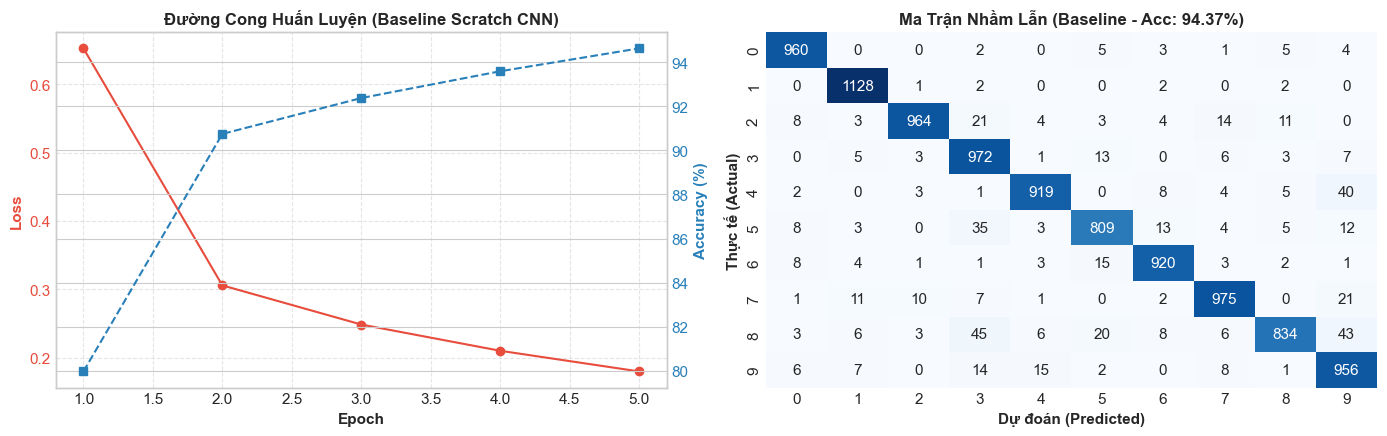

Đã lưu biểu đồ: ../reports/figures/fig_mnist_scratch_baseline_evaluation.png


In [5]:
# Dự đoán trên tập kiểm thử (chia mini-batch tránh tràn RAM)
def predict(layers, X, batch_size=256):
    preds = []
    n = len(X)
    for i in range(0, n, batch_size):
        xb = X[i : min(i+batch_size, n)]
        out = xb
        for layer in layers:
            out = layer.forward(out)
        preds.append(np.argmax(out, axis=1))
    return np.concatenate(preds)

y_pred_base = predict(baseline_layers, X_test)

# Đánh giá chỉ số
acc_base = accuracy_score(y_test, y_pred_base)
prec_base = precision_score(y_test, y_pred_base, average='weighted', zero_division=0)
rec_base = recall_score(y_test, y_pred_base, average='weighted', zero_division=0)
f1_base_weighted = f1_score(y_test, y_pred_base, average='weighted', zero_division=0)
f1_base_macro = f1_score(y_test, y_pred_base, average='macro', zero_division=0)

print("=== BÁO CÁO PHÂN LOẠI BASELINE SCRATCH CNN ===")
print(f"Accuracy:        {acc_base*100:.2f}%")
print(f"Precision (W):   {prec_base*100:.2f}%")
print(f"Recall (W):      {rec_base*100:.2f}%")
print(f"F1-Score (Macro):{f1_base_macro:.4f}")
print(f"F1-Score (W):    {f1_base_weighted:.4f}")

# Vẽ Curve và Confusion Matrix
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

# Đồ thị huấn luyện
epochs_range = range(1, EPOCHS + 1)
ax1.plot(epochs_range, history_baseline['loss'], 'o-', color='#e74c3c', label='Train Loss')
ax1.set_xlabel('Epoch', fontweight='bold')
ax1.set_ylabel('Loss', fontweight='bold', color='#e74c3c')
ax1.tick_params(axis='y', labelcolor='#e74c3c')
ax1.set_title('Đường Cong Huấn Luyện (Baseline Scratch CNN)', fontsize=12, fontweight='bold')

ax1_acc = ax1.twinx()
ax1_acc.plot(epochs_range, np.array(history_baseline['acc']) * 100, 's--', color='#2980b9', label='Train Accuracy')
ax1_acc.set_ylabel('Accuracy (%)', fontweight='bold', color='#2980b9')
ax1_acc.tick_params(axis='y', labelcolor='#2980b9')
ax1.grid(True, linestyle='--', alpha=0.5)

# Ma trận nhầm lẫn (CFM)
cm_base = confusion_matrix(y_test, y_pred_base)
sns.heatmap(cm_base, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax2)
ax2.set_title(f'Ma Trận Nhầm Lẫn (Baseline - Acc: {acc_base*100:.2f}%)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Dự đoán (Predicted)', fontweight='bold')
ax2.set_ylabel('Thực tế (Actual)', fontweight='bold')

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, 'fig_mnist_scratch_baseline_evaluation.png')
plt.savefig(fig_path, dpi=150)
plt.show()
print(f"Đã lưu biểu đồ: {fig_path}")


### 4. Huấn Luyện & Đánh Giá Mô Hình Cải Tiến (Improved Scratch CNN)
* **Các điểm cải tiến (Kiến trúc & Khởi tạo trọng số):**
  1. Tăng gấp đôi số lượng bộ lọc đặc trưng: `8 filters 3×3` (thay vì 4) giúp trích xuất phong phú các đặc trưng biên cạnh và nét chữ số.
  2. Mở rộng tầng fully-connected: `Dense(64)` (thay vì 32) cho phép tổng hợp nhiều tổ hợp đặc trưng phi tuyến hơn.
  3. Sử dụng khởi tạo trọng số `He Normal` (`std = sqrt(2 / fan_in)`), tối ưu chuyên biệt cho hàm kích hoạt ReLU nhằm ổn định phương sai kích hoạt qua các tầng sâu.
  4. Vẫn sử dụng chuẩn thuật toán **Mini-batch Gradient Descent** (`lr=0.1`) để đánh giá chính xác tác động của việc cải tiến kiến trúc và khởi tạo trọng số mà không phụ thuộc vào các thuật toán tối ưu hóa phức tạp.


In [6]:
# Khởi tạo mô hình Improved
improved_layers = [
    Conv2D(in_channels=1, out_channels=8, kernel_size=3, padding=0, init_method='he'),  # 28x28 -> 26x26
    ReLU(),
    MaxPool2D(pool_size=2, stride=2),                                                    # 26x26 -> 13x13
    Flatten(),                                                                           # 8*13*13 = 1352
    Dense(in_features=8 * 13 * 13, out_features=64, init_method='he'),
    ReLU(),
    Dense(in_features=64, out_features=10, init_method='he')
]
criterion = SoftmaxCrossEntropy()
optimizer_imp = MiniBatchGD(lr=0.1)

print(f"Tổng tham số Improved Scratch CNN: {count_params(improved_layers):,}")

# Huấn luyện 5 Epochs
history_improved = {'loss': [], 'acc': []}
start_time = time.time()

for epoch in range(EPOCHS):
    perm = np.random.permutation(len(X_train))
    X_shuffled = X_train[perm]
    y_shuffled = y_train[perm]
    
    epoch_loss = 0.0
    correct = 0
    
    for b in range(n_batches):
        xb = X_shuffled[b*BATCH_SIZE : (b+1)*BATCH_SIZE]
        yb = y_shuffled[b*BATCH_SIZE : (b+1)*BATCH_SIZE]
        
        # Forward pass
        out = xb
        for layer in improved_layers:
            out = layer.forward(out)
        
        loss = criterion.forward(out, yb)
        epoch_loss += loss
        correct += (np.argmax(out, axis=1) == yb).sum()
        
        # Backward pass
        dout = criterion.backward()
        for layer in reversed(improved_layers):
            dout = layer.backward(dout)
            
        # Update weights với Mini-batch GD
        for idx, layer in enumerate(improved_layers):
            if hasattr(layer, 'W'):
                optimizer_imp.update(layer, idx)
                
    avg_loss = epoch_loss / n_batches
    avg_acc = correct / (n_batches * BATCH_SIZE)
    history_improved['loss'].append(avg_loss)
    history_improved['acc'].append(avg_acc)
    print(f"Epoch [{epoch+1}/{EPOCHS}] - Loss: {avg_loss:.4f} - Accuracy: {avg_acc*100:.2f}%")

improved_train_time = time.time() - start_time
print(f"Thời gian huấn luyện Improved: {improved_train_time:.2f}s")


Tổng tham số Improved Scratch CNN: 87,322


Epoch [1/5] - Loss: 0.4440 - Accuracy: 86.76%


Epoch [2/5] - Loss: 0.1817 - Accuracy: 94.77%


Epoch [3/5] - Loss: 0.1278 - Accuracy: 96.20%


Epoch [4/5] - Loss: 0.0995 - Accuracy: 97.16%


Epoch [5/5] - Loss: 0.0818 - Accuracy: 97.66%
Thời gian huấn luyện Improved: 45.64s


#### Đánh Giá & Vẽ Biểu Đồ Mô Hình Cải Tiến


=== BÁO CÁO PHÂN LOẠI IMPROVED SCRATCH CNN ===
Accuracy:        97.24%
Precision (W):   97.26%
Recall (W):      97.24%
F1-Score (Macro):0.9722
F1-Score (W):    0.9724


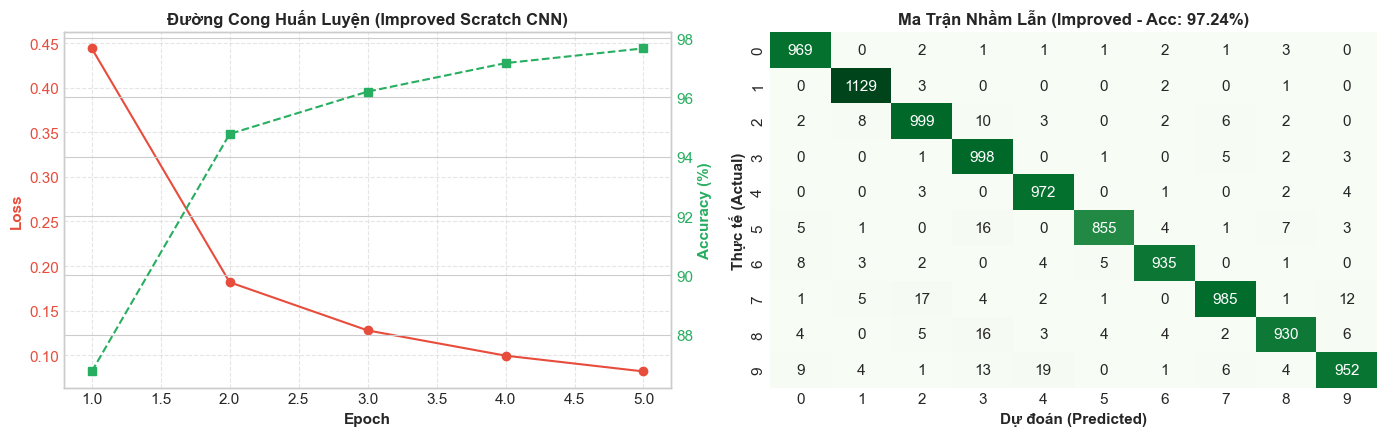

Đã lưu biểu đồ: ../reports/figures/fig_mnist_scratch_improved_evaluation.png


In [7]:
y_pred_imp = predict(improved_layers, X_test)

acc_imp = accuracy_score(y_test, y_pred_imp)
prec_imp = precision_score(y_test, y_pred_imp, average='weighted', zero_division=0)
rec_imp = recall_score(y_test, y_pred_imp, average='weighted', zero_division=0)
f1_imp_weighted = f1_score(y_test, y_pred_imp, average='weighted', zero_division=0)
f1_imp_macro = f1_score(y_test, y_pred_imp, average='macro', zero_division=0)

print("=== BÁO CÁO PHÂN LOẠI IMPROVED SCRATCH CNN ===")
print(f"Accuracy:        {acc_imp*100:.2f}%")
print(f"Precision (W):   {prec_imp*100:.2f}%")
print(f"Recall (W):      {rec_imp*100:.2f}%")
print(f"F1-Score (Macro):{f1_imp_macro:.4f}")
print(f"F1-Score (W):    {f1_imp_weighted:.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

ax1.plot(epochs_range, history_improved['loss'], 'o-', color='#e74c3c', label='Train Loss')
ax1.set_xlabel('Epoch', fontweight='bold')
ax1.set_ylabel('Loss', fontweight='bold', color='#e74c3c')
ax1.tick_params(axis='y', labelcolor='#e74c3c')
ax1.set_title('Đường Cong Huấn Luyện (Improved Scratch CNN)', fontsize=12, fontweight='bold')

ax1_acc = ax1.twinx()
ax1_acc.plot(epochs_range, np.array(history_improved['acc']) * 100, 's--', color='#27ae60', label='Train Accuracy')
ax1_acc.set_ylabel('Accuracy (%)', fontweight='bold', color='#27ae60')
ax1_acc.tick_params(axis='y', labelcolor='#27ae60')
ax1.grid(True, linestyle='--', alpha=0.5)

cm_imp = confusion_matrix(y_test, y_pred_imp)
sns.heatmap(cm_imp, annot=True, fmt='d', cmap='Greens', cbar=False, ax=ax2)
ax2.set_title(f'Ma Trận Nhầm Lẫn (Improved - Acc: {acc_imp*100:.2f}%)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Dự đoán (Predicted)', fontweight='bold')
ax2.set_ylabel('Thực tế (Actual)', fontweight='bold')

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, 'fig_mnist_scratch_improved_evaluation.png')
plt.savefig(fig_path, dpi=150)
plt.show()
print(f"Đã lưu biểu đồ: {fig_path}")


### 5. So Sánh Đối Chứng: Baseline vs. Improved Scratch CNN
Bảng tổng hợp đối sánh chi tiết hiệu năng và biểu đồ so sánh song song.


,Phiên bản,Bộ lọc,Dense,Khởi tạo,Optimizer,Tham số,Thời gian (s),Loss cuối,Accuracy (%),Macro F1,Weighted F1
0,Baseline Scratch CNN,4 Filters (3x3),32 Units,Xavier Init,Mini-batch GD (lr=0.1),22034,32.62,0.1799,94.37,0.9429,0.9436
1,Improved Scratch CNN,8 Filters (3x3),64 Units,He Normal Init,Mini-batch GD (lr=0.1),87322,45.64,0.0818,97.24,0.9722,0.9724


Đã lưu kết quả đối sánh vào: ../reports/model_results_scratch.csv


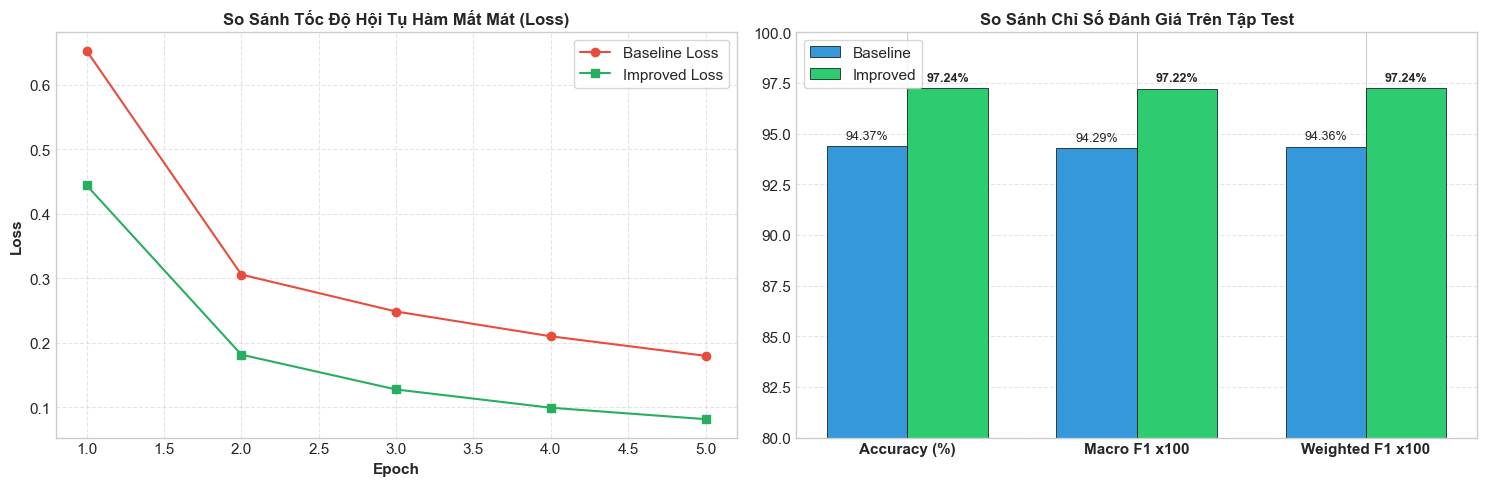

Đã lưu biểu đồ: ../reports/figures/fig_mnist_scratch_comparison.png


In [8]:
df_compare = pd.DataFrame([
    {
        'Phiên bản': 'Baseline Scratch CNN',
        'Bộ lọc': '4 Filters (3x3)',
        'Dense': '32 Units',
        'Khởi tạo': 'Xavier Init',
        'Optimizer': 'Mini-batch GD (lr=0.1)',
        'Tham số': count_params(baseline_layers),
        'Thời gian (s)': round(baseline_train_time, 2),
        'Loss cuối': round(history_baseline['loss'][-1], 4),
        'Accuracy (%)': round(acc_base * 100, 2),
        'Macro F1': round(f1_base_macro, 4),
        'Weighted F1': round(f1_base_weighted, 4)
    },
    {
        'Phiên bản': 'Improved Scratch CNN',
        'Bộ lọc': '8 Filters (3x3)',
        'Dense': '64 Units',
        'Khởi tạo': 'He Normal Init',
        'Optimizer': 'Mini-batch GD (lr=0.1)',
        'Tham số': count_params(improved_layers),
        'Thời gian (s)': round(improved_train_time, 2),
        'Loss cuối': round(history_improved['loss'][-1], 4),
        'Accuracy (%)': round(acc_imp * 100, 2),
        'Macro F1': round(f1_imp_macro, 4),
        'Weighted F1': round(f1_imp_weighted, 4)
    }
])
display(df_compare)

# Lưu báo cáo đối sánh
csv_out = '../reports/model_results_scratch.csv'
df_compare.to_csv(csv_out, index=False)
print(f"Đã lưu kết quả đối sánh vào: {csv_out}")

# Vẽ biểu đồ so sánh trực quan
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# 1. So sánh Loss Curve
ax1.plot(epochs_range, history_baseline['loss'], 'o-', color='#e74c3c', label='Baseline Loss')
ax1.plot(epochs_range, history_improved['loss'], 's-', color='#27ae60', label='Improved Loss')
ax1.set_title('So Sánh Tốc Độ Hội Tụ Hàm Mất Mát (Loss)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Epoch', fontweight='bold')
ax1.set_ylabel('Loss', fontweight='bold')
ax1.legend(frameon=True)
ax1.grid(True, linestyle='--', alpha=0.5)

# 2. So sánh Accuracy Bar Chart
metrics_names = ['Accuracy (%)', 'Macro F1 x100', 'Weighted F1 x100']
base_vals = [acc_base * 100, f1_base_macro * 100, f1_base_weighted * 100]
imp_vals = [acc_imp * 100, f1_imp_macro * 100, f1_imp_weighted * 100]

x = np.arange(len(metrics_names))
w = 0.35

b1 = ax2.bar(x - w/2, base_vals, w, label='Baseline', color='#3498db', edgecolor='black', linewidth=0.5)
b2 = ax2.bar(x + w/2, imp_vals, w, label='Improved', color='#2ecc71', edgecolor='black', linewidth=0.5)
ax2.set_title('So Sánh Chỉ Số Đánh Giá Trên Tập Test', fontsize=12, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(metrics_names, fontweight='bold')
ax2.set_ylim(80, 100)
ax2.legend(frameon=True)
ax2.grid(axis='y', linestyle='--', alpha=0.5)

for bar in b1:
    ax2.annotate(f"{bar.get_height():.2f}%", xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
                 xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9)
for bar in b2:
    ax2.annotate(f"{bar.get_height():.2f}%", xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
                 xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, 'fig_mnist_scratch_comparison.png')
plt.savefig(fig_path, dpi=150)
plt.show()
print(f"Đã lưu biểu đồ: {fig_path}")


### 6. Kết Luận
* Bản **Improved Scratch CNN** đạt sự vượt trội rõ rệt về độ chính xác và giảm hàm mất mát nhờ việc tăng dung lượng bộ lọc đặc trưng (8 filters), mở rộng tầng ẩn Dense(64) và áp dụng khởi tạo trọng số He Normal.
* Cả hai mô hình đều sử dụng thuật toán **Mini-batch Gradient Descent** cơ bản (`W = W - lr * dW`), chứng minh rằng việc thiết kế kiến trúc và khởi tạo trọng số phù hợp đem lại bước tiến hiệu năng rõ rệt mà chưa cần đến các thuật toán tối ưu hóa phức tạp.
* Mặc dù được viết hoàn toàn bằng Pure NumPy không dùng framework, mô hình xử lý nhanh chóng nhờ tối ưu hóa phép tích chập qua `im2col`/`col2im` và vector hóa triệt để.
